# Telco Customer Churn - Exploratory Data Analysis

## Objective

The goal of this notebook is to understand the dataset, identify data quality issues, and explore patterns related to customer churn.

## 1. Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_column', None)

## 2. Load Dataset

In [2]:
df = pd.read_csv("../data/telco_customer_churn.csv")

## 3. Dataset Overview

In [3]:
df.shape

(7043, 21)

In [4]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [5]:
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [7]:
df.nunique()

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

In [8]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [9]:
target_col = "Churn"

### Initial Observations

- The dataset contains 7,043 rows and 21 columns.
- The target variable is Churn.
- The 'TotalCharges' column is initially stored as a string.
- The 'customerID' column contains 7,043 unique values.

## 4. Data Quality Assessment

In [10]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

total_charges_numeric.isna().sum()

np.int64(11)

In [13]:
df.loc[
    total_charges_numeric.isna(),
    ["tenure", "TotalCharges"]
]

,tenure,TotalCharges
488,0,
753,0,
936,0,
1082,0,
1340,0,
3331,0,
3826,0,
4380,0,
5218,0,
6670,0,


There are 11 records with missing TotalCharges values. All these customers have a tenure of 0 months. This suggests that they are new customers who may not have been billed yet.

## 5. Data Cleaning

In [14]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

df.loc[df["tenure"] == 0, "TotalCharges"] = df.loc[df["tenure"] == 0, "TotalCharges"].fillna(0.0)


In [15]:
df["TotalCharges"].dtype

dtype('float64')

In [16]:
df["TotalCharges"].isna().sum()

np.int64(0)

In [17]:
df.shape

(7043, 21)

The TotalCharges column was converted to a numeric data type. The 11 missing values belonged to customers with zero tenure, so they were filled with 0.0 under the assumption that these customers had not yet accumulated charges. No rows were removed.

## 6. Target Variable Analysis

In [18]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [19]:
df['Churn'].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

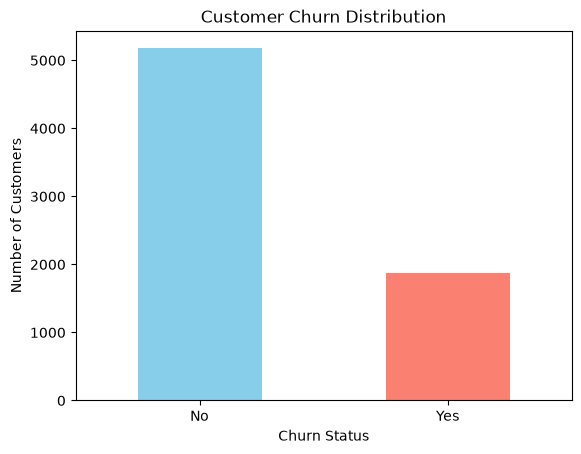

In [20]:
df['Churn'].value_counts().plot(
    kind='bar',
    color=['skyblue', 'salmon']
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

### Observations
- Approximately 26.54% of customers churned.
- The dataset has imbalanced target classes.
- We should not rely on accuracy alone when evaluating the model.
- A model that always predicts "No" would achieve approximately 73.46% accuracy without identifying any customers who churned.

## 7. Numerical Features Analysis

## 8. Categorical Features Analysis

## 9. Feature Relationships with Churn

## 10. Key Findings